# SWYNEX Task 1 — Dataset Exploration & Preprocessing

**Internship:** Machine Learning Internship  
**Dataset:** Titanic passenger dataset  
**Objective:** Explore the data, inspect and handle missing values, encode categorical variables, and prepare features for model training.

**Source:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv

Run all cells from top to bottom. An internet connection is required to download the dataset.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load the dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(DATA_URL)
print("Dataset loaded successfully")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Initial exploration

In [3]:
print("Columns:", df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()
print("\\nNumerical summary:")
display(df.describe())
print("\\nCategorical summary:")
display(df.describe(include="object"))

Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


\nCategorical summary:


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


## 4. Missing values and duplicates

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)
print("Duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


Duplicate rows: 107


## 5. Exploratory data analysis

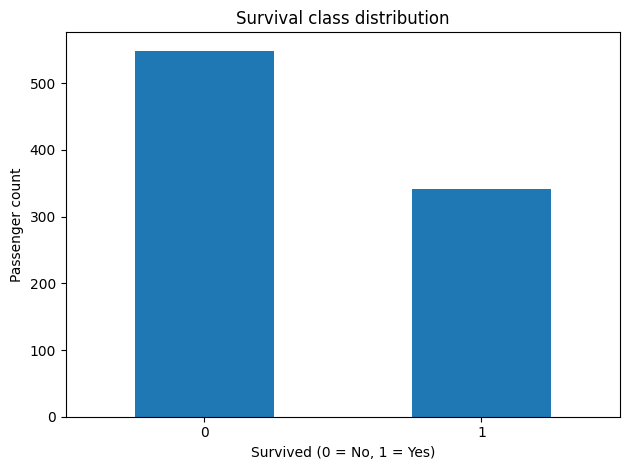

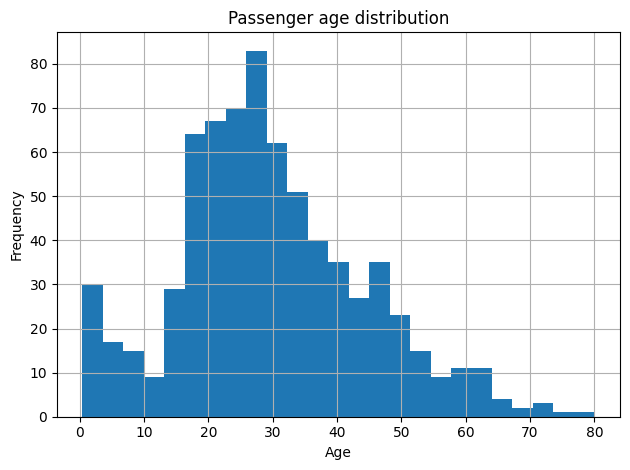

,survival_rate
sex,
female,0.742038
male,0.188908


In [5]:
df["survived"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.title("Survival class distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Passenger count")
plt.tight_layout()
plt.show()

df["age"].hist(bins=25)
plt.title("Passenger age distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df.groupby("sex", observed=False)["survived"].mean().to_frame("survival_rate"))

## 6. Select features and target

The `alive` column is excluded because it directly describes the target and would cause target leakage. The `deck` column is excluded because it has substantial missingness. The selected target is `survived`.

In [6]:
selected_columns = [
    "survived", "pclass", "age", "sibsp", "parch",
    "fare", "sex", "embarked", "alone"
]
data = df[selected_columns].dropna(subset=["survived"]).copy()
X = data.drop(columns="survived")
y = data["survived"].astype(int)

numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked", "alone"]
print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Target classes:", sorted(y.unique()))

Feature matrix: (891, 8)
Target vector: (891,)
Target classes: [np.int64(0), np.int64(1)]


## 7. Split the data before fitting preprocessing

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


## 8. Handle missing values and encode categorical variables

Preprocessing is fitted only on the training data to reduce data leakage. Numeric values use median imputation and standard scaling. Categorical values use most-frequent imputation and one-hot encoding.

In [8]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (712, 12)
Processed testing shape: (179, 12)


## 9. Verify processed features

In [9]:
feature_names = preprocessor.get_feature_names_out()
train_array = X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed
test_array = X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed

X_train_ready = pd.DataFrame(train_array, columns=feature_names, index=X_train.index)
X_test_ready = pd.DataFrame(test_array, columns=feature_names, index=X_test.index)
display(X_train_ready.head())
print("Missing values after preprocessing:", int(X_train_ready.isna().sum().sum()))

,numeric__pclass,numeric__age,numeric__sibsp,numeric__parch,numeric__fare,categorical__sex_female,categorical__sex_male,categorical__embarked_C,categorical__embarked_Q,categorical__embarked_S,categorical__alone_False,categorical__alone_True
692,0.829568,-0.081135,-0.465084,-0.466183,0.513812,0.0,1.0,0.0,0.0,1.0,0.0,1.0
481,-0.370945,-0.081135,-0.465084,-0.466183,-0.662563,0.0,1.0,0.0,0.0,1.0,0.0,1.0
527,-1.571457,-0.081135,-0.465084,-0.466183,3.955399,0.0,1.0,0.0,0.0,1.0,0.0,1.0
855,0.829568,-0.887827,-0.465084,0.727782,-0.467874,1.0,0.0,0.0,0.0,1.0,1.0,0.0
801,-0.370945,0.110934,0.478335,0.727782,-0.115977,1.0,0.0,0.0,0.0,1.0,1.0,0.0


Missing values after preprocessing: 0


## 10. Export model-ready data

In [10]:
output_dir = "processed_data"
os.makedirs(output_dir, exist_ok=True)
X_train_ready.to_csv(f"{output_dir}/X_train_processed.csv", index=False)
X_test_ready.to_csv(f"{output_dir}/X_test_processed.csv", index=False)
y_train.to_csv(f"{output_dir}/y_train.csv", index=False, header=["survived"])
y_test.to_csv(f"{output_dir}/y_test.csv", index=False, header=["survived"])
print("Processed feature and target files exported to:", output_dir)

Processed feature and target files exported to: processed_data


## 11. Conclusion

The Titanic dataset was loaded and explored using shape, data types, descriptive statistics, missing-value analysis, and visualizations. A feature set and target were selected. The data was split into training and test sets before preprocessing. Numeric missing values were filled with the median and scaled. Categorical missing values were filled with the most frequent value and one-hot encoded.

`X_train_ready` and `X_test_ready` are prepared for a later machine-learning model. **No predictive model is trained in Task 1.**

**Reproducibility:** test size 20%, random state 42, preprocessing implemented with scikit-learn pipelines.